# Choosing the Right Classification Metric
### CSC 2611 · AI Tools · Four real-world decisions

A classifier can make two kinds of errors: flag something that is actually negative (**false positive**), or miss something that is actually positive (**false negative**). Their consequences depend on the application.

Each case below describes a decision, the consequences of mistakes, and illustrative performance from several candidate classifiers. The examples are constructed for classroom comparison; they are not trained or deployed models.

| Metric | What it measures |
|---|---|
| **Accuracy** | Correct predictions divided by all predictions |
| **Precision** | Correct positive predictions divided by all positive predictions |
| **Recall** | Correct positive predictions divided by all actual positive cases |
| **F1** | Harmonic mean of precision and recall |

In each example, **positive** refers to the specific event or class identified in that section.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Fixed, illustrative confusion-matrix counts: not results from trained models.
def compare_models(models, positive_label, title):
    records = []
    for name, (tp, fp, fn, tn) in models.items():
        p = tp / (tp + fp) if tp + fp else 0
        r = tp / (tp + fn) if tp + fn else 0
        records.append(dict(Model=name, Accuracy=(tp + tn)/(tp + tn + fp + fn), Precision=p, Recall=r,
                            F1=(2*p*r/(p+r) if p+r else 0),
                            **{'False alarms (FP)':fp, 'Misses (FN)':fn}))
    df = pd.DataFrame(records).set_index('Model')
    ax = df[['False alarms (FP)','Misses (FN)']].plot(kind='bar', figsize=(9,3.6), rot=0)
    ax.set_title(title + ' — consequences per 1,000 examples')
    ax.set_ylabel('Number of mistakes'); ax.set_xlabel('')
    ax.legend(frameon=False); plt.tight_layout(); plt.show()
    print('POSITIVE CLASS:', positive_label)
    display(df.style.format({m:'{:.1%}' for m in ['Accuracy','Precision','Recall','F1']}))
    return df


## Scenario 1 — Product sorting

A camera-based packaging line must distinguish **Product A** from **Product B**. The evaluation sample contains 500 of each. Errors in either direction have approximately equal consequences: a worker must inspect and correct the sorted item.

**Positive class:** Product A.

Two candidate classifiers were tested on the same 1,000 examples. Their confusion-matrix counts and metric summaries appear below.


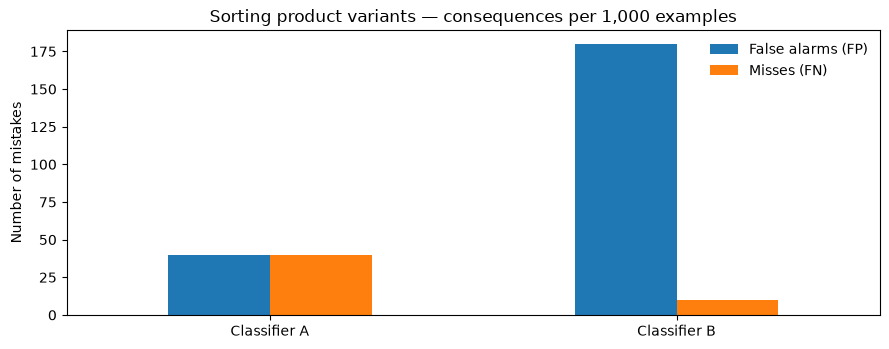

POSITIVE CLASS: Product A


,Accuracy,Precision,Recall,F1,False alarms (FP),Misses (FN)
Model,,,,,,
Classifier A,92.0%,92.0%,92.0%,92.0%,40,40
Classifier B,81.0%,73.1%,98.0%,83.8%,180,10


In [2]:
s1 = compare_models({
    'Classifier A': (460,40,40,460),
    'Classifier B': (490,180,10,320),
}, 'Product A', 'Sorting product variants')

**Operational context:** A production manager cares about the number of correctly routed items across the line. The costs of confusing A with B and B with A are similar. If one product later became very rare, the operating context would change.


---
## Scenario 2 — Automatic email deletion

An organization considers a security tool that **permanently deletes** messages classified as malicious. Of 1,000 messages, 100 are malicious and 900 are legitimate.

**Positive class:** Malicious email.

- **False positive:** A legitimate message is deleted and could be lost permanently.
- **False negative:** A malicious message gets through this particular filter.

An accidentally deleted purchase order or customer message can carry a major business cost. Other security protections are also present, and a less destructive quarantine workflow is possible.

Compare the outcomes of two candidate policies below.


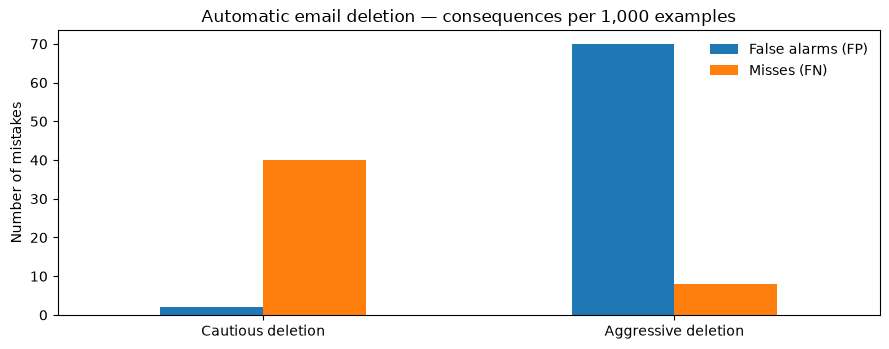

POSITIVE CLASS: Malicious email


,Accuracy,Precision,Recall,F1,False alarms (FP),Misses (FN)
Model,,,,,,
Cautious deletion,95.8%,96.8%,60.0%,74.1%,2,40
Aggressive deletion,92.2%,56.8%,92.0%,70.2%,70,8


In [3]:
s2 = compare_models({
    'Cautious deletion': (60,2,40,898),
    'Aggressive deletion': (92,70,8,830),
}, 'Malicious email', 'Automatic email deletion')

**Operational context:** An automated deletion action is difficult to undo. The practical consequences differ from a quarantine system in which a user can recover misclassified messages. Model selection depends in part on which action the positive prediction triggers.


---
## Scenario 3 — Screening battery packs for a dangerous defect

A manufacturing line screens 1,000 battery packs. Of these, **50 have a potentially dangerous defect** and **950 are safe**. Packs flagged by the model receive a **secondary inspection** rather than being immediately discarded.

**Positive class:** Defective battery pack.

- **False positive:** A safe pack requires an unnecessary inspection.
- **False negative:** A defective pack is missed by screening and continues down the line.

Inspection consumes time and capacity. Allowing a dangerous defect to escape may have much more serious consequences.

Compare the two candidate screening systems below.


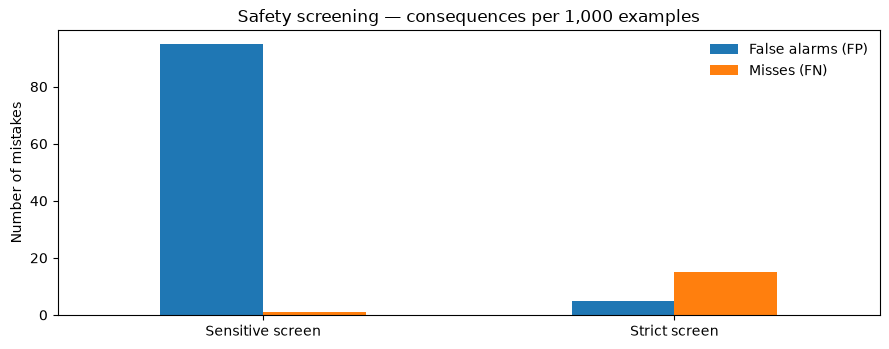

POSITIVE CLASS: Defective battery pack


,Accuracy,Precision,Recall,F1,False alarms (FP),Misses (FN)
Model,,,,,,
Sensitive screen,90.4%,34.0%,98.0%,50.5%,95,1
Strict screen,98.0%,87.5%,70.0%,77.8%,5,15


In [4]:
s3 = compare_models({
    'Sensitive screen': (49,95,1,855),
    'Strict screen': (35,5,15,945),
}, 'Defective battery pack', 'Safety screening')

**Operational context:** This model serves as an initial safety screen. The inspection station has finite capacity, so the number of flagged packs matters alongside the number of defects missed.


---
## Scenario 4 — Flagging transactions for fraud review

A payment platform routes suspicious transactions to human reviewers. Among 1,000 transactions, **100 are fraudulent** and **900 are legitimate**. A flag triggers **review**, not automatic denial.

**Positive class:** Fraudulent transaction.

- **False positive:** A legitimate transaction consumes analyst time and may delay the customer.
- **False negative:** Fraud is not flagged for review and may produce financial loss.

The review team cannot investigate an unlimited number of transactions; however, missed fraud can be costly. Compare three policies with different mixes of missed fraud and review workload.


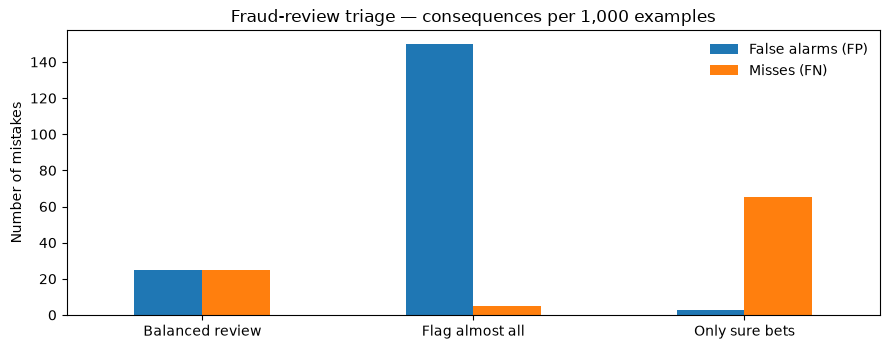

POSITIVE CLASS: Fraudulent transaction


,Accuracy,Precision,Recall,F1,False alarms (FP),Misses (FN)
Model,,,,,,
Balanced review,95.0%,75.0%,75.0%,75.0%,25,25
Flag almost all,84.5%,38.8%,95.0%,55.1%,150,5
Only sure bets,93.2%,92.1%,35.0%,50.7%,3,65


In [5]:
s4 = compare_models({
    'Balanced review': (75,25,25,875),
    'Flag almost all': (95,150,5,750),
    'Only sure bets': (35,3,65,897),
}, 'Fraudulent transaction', 'Fraud-review triage')

**Operational context:** The review queue must be manageable, while a substantial share of fraudulent transactions should still be detected. The chosen policy should ultimately respect both business costs and review capacity.


---
## Takeaway — Model evaluation is an application decision

These examples use the same four metrics, but the cost of errors changes across applications.

A good evaluation plan specifies the **positive class**, defines what **false positives** and **false negatives** mean in the product, and identifies the real-world consequences before selecting a performance target.

This judgment still applies when the underlying model is a deep neural network: a more complex model does not automatically imply a better decision policy.
